# Kumasi Waste Collection Demand Prediction

### Final Machine Learning Model

**Objective:** Predict waste collection demand (kg) at different locations in Kumasi.



In [13]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load and Inspect the Dataset

In [2]:
df = pd.read_csv("Kumasi_Waste_Collection_Demand_Dataset.csv")
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (1500, 19)


In [4]:
display(df.head())

,record_id,date,month,day_of_week,is_weekend,location,area_type,population_activity_index,is_market_day,roadside_activity_index,rainfall_mm,days_since_collection,collection_frequency_per_week,container_count,container_capacity_litres,previous_waste_kg,waste_accumulation_index,container_utilization_ratio,waste_collection_demand_kg
0,1,2025-10-10,October,Friday,0,Bantama,Mixed,3,0,5,7.5,5,1,5,1500,1116.0,9,0.324,1824.5
1,2,2025-12-05,December,Friday,0,Ayigya,Mixed,5,0,6,4.7,3,2,6,2200,1045.0,8,0.157,1552.5
2,3,2025-12-21,December,Sunday,1,Kumasi Central Market,Market,7,0,5,1.3,1,7,5,1500,1075.2,6,0.243,1367.4
3,4,2025-05-16,May,Friday,0,Abrepo,Residential,4,0,4,2.1,1,7,6,1100,744.4,5,0.228,1126.7
4,5,2025-05-22,May,Thursday,0,Abrepo,Residential,3,0,4,3.5,1,7,5,1500,544.4,5,0.159,894.7


In [ ]:
print(df.shape)

In [ ]:
df.info()

In [ ]:
if "df" not in globals():
    df = pd.read_csv("Kumasi_Waste_Collection_Demand_Dataset.csv")

display(df.describe().T.round(2))

In [10]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

Duplicate rows: 0

Missing values:


,Missing Values
record_id,0
date,0
month,0
day_of_week,0
is_weekend,0
location,0
area_type,0
population_activity_index,0
is_market_day,0
roadside_activity_index,0


## 2. Understand the Target Variable

In [14]:
TARGET = "waste_collection_demand_kg"
display(df[TARGET].describe().to_frame().round(2))

,waste_collection_demand_kg
count,1500.00
mean,1328.33
std,351.45
min,382.40
25%,1076.20
50%,1301.05
75%,1561.95
max,2658.00


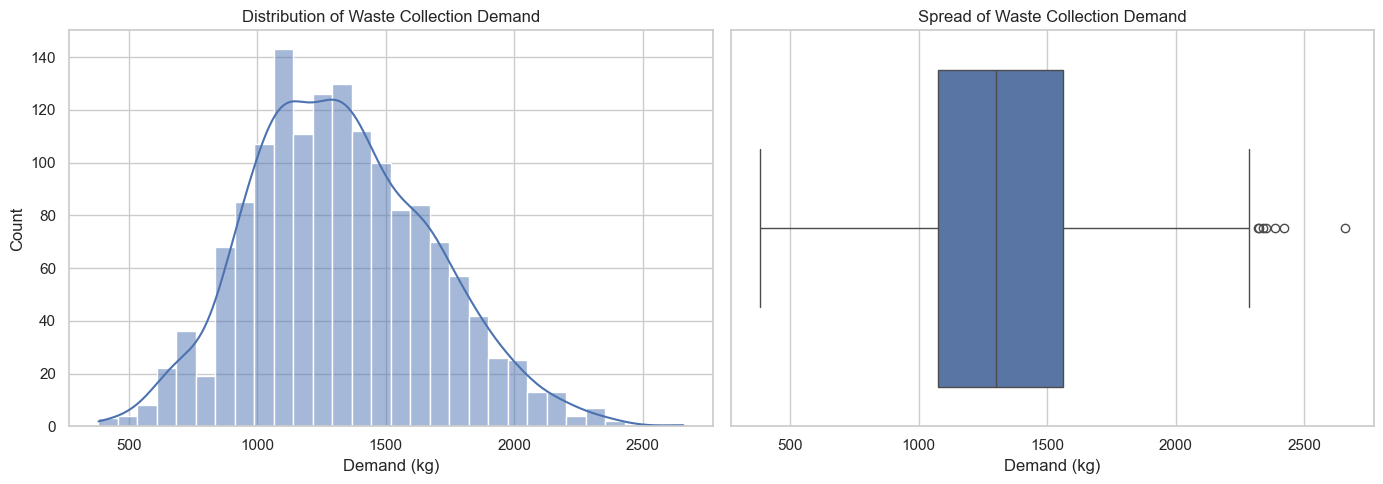

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[TARGET], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Waste Collection Demand")
axes[0].set_xlabel("Demand (kg)")

sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("Spread of Waste Collection Demand")
axes[1].set_xlabel("Demand (kg)")

plt.tight_layout()
plt.show()

## 3. Exploratory Data Analysis

In [16]:
location_summary = (
    df.groupby("location")[TARGET]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)
display(location_summary.round(2))

,count,mean,median,min,max
location,,,,,
Kumasi Central Market,129,1778.46,1758.10,981.4,2385.8
Tafo,118,1558.99,1562.65,858.5,2421.9
Suame,125,1421.36,1370.60,735.3,2171.8
Ayigya,132,1364.42,1332.20,647.6,2172.1
Asokwa,129,1340.89,1315.50,622.6,2168.4
Sofoline,126,1340.47,1331.00,581.4,2658.0
Bantama,137,1284.20,1304.60,561.0,1977.6
Manhyia,119,1247.88,1202.00,503.5,2323.3
Oforikrom,111,1203.83,1195.20,409.2,2047.9


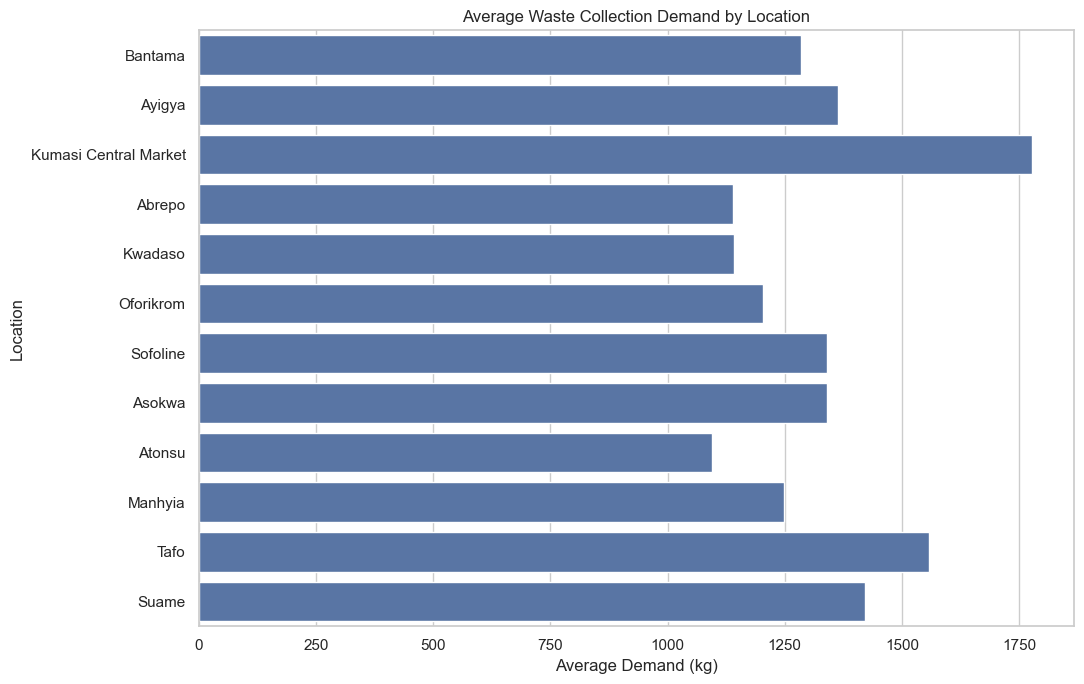

In [17]:
plt.figure(figsize=(11, 7))
sns.barplot(data=df, x=TARGET, y="location", estimator=np.mean, errorbar=None)
plt.title("Average Waste Collection Demand by Location")
plt.xlabel("Average Demand (kg)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

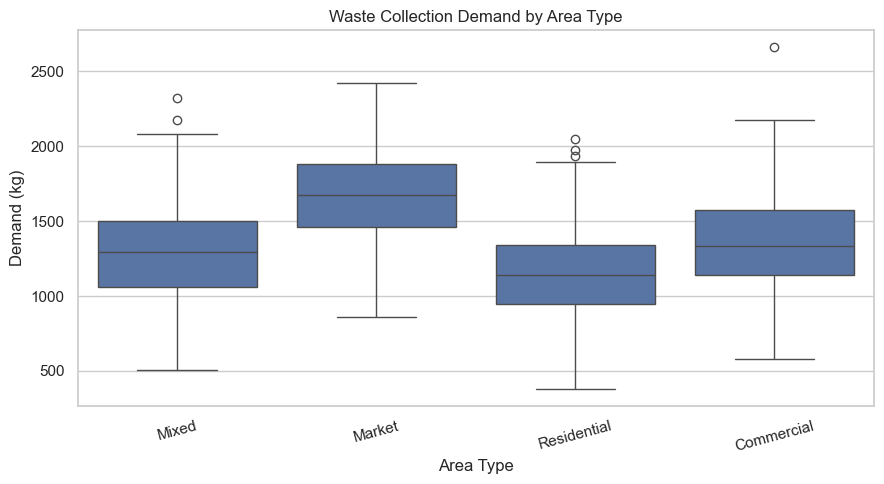

In [18]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="area_type", y=TARGET)
plt.title("Waste Collection Demand by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Demand (kg)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

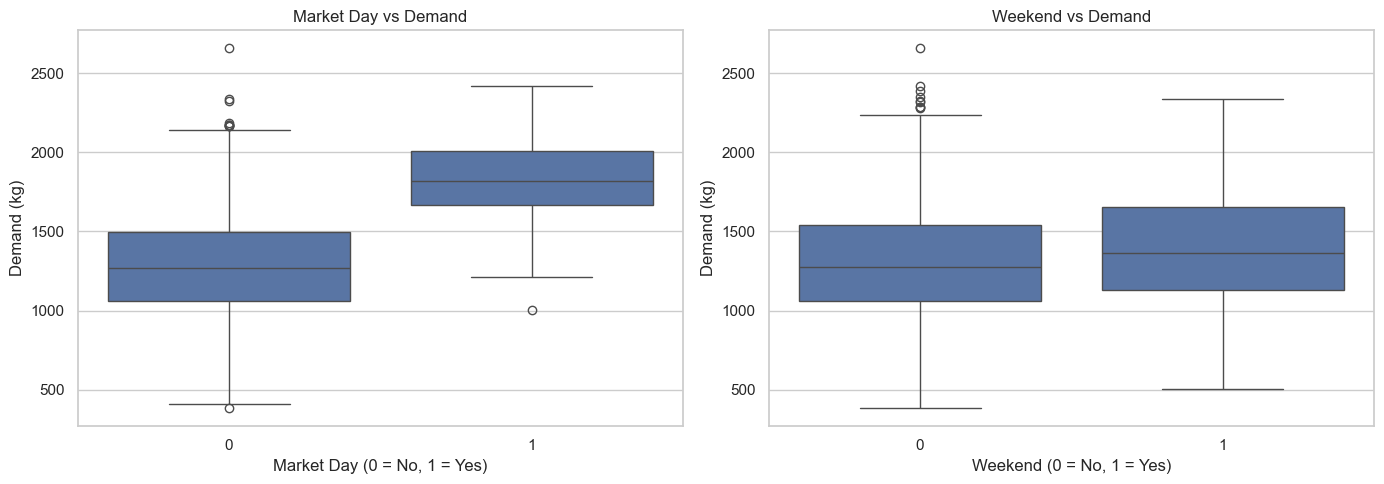

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="is_market_day", y=TARGET, ax=axes[0])
axes[0].set_title("Market Day vs Demand")
axes[0].set_xlabel("Market Day (0 = No, 1 = Yes)")
axes[0].set_ylabel("Demand (kg)")

sns.boxplot(data=df, x="is_weekend", y=TARGET, ax=axes[1])
axes[1].set_title("Weekend vs Demand")
axes[1].set_xlabel("Weekend (0 = No, 1 = Yes)")
axes[1].set_ylabel("Demand (kg)")

plt.tight_layout()
plt.show()

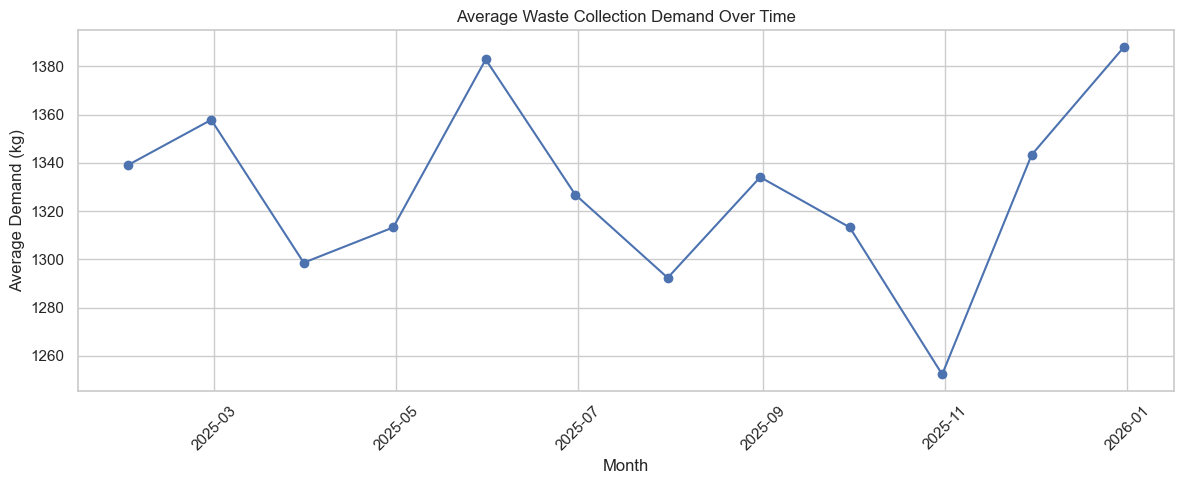

In [20]:
df["date"] = pd.to_datetime(df["date"])

monthly = df.set_index("date")[TARGET].resample("ME").mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Average Waste Collection Demand Over Time")
plt.xlabel("Month")
plt.ylabel("Average Demand (kg)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

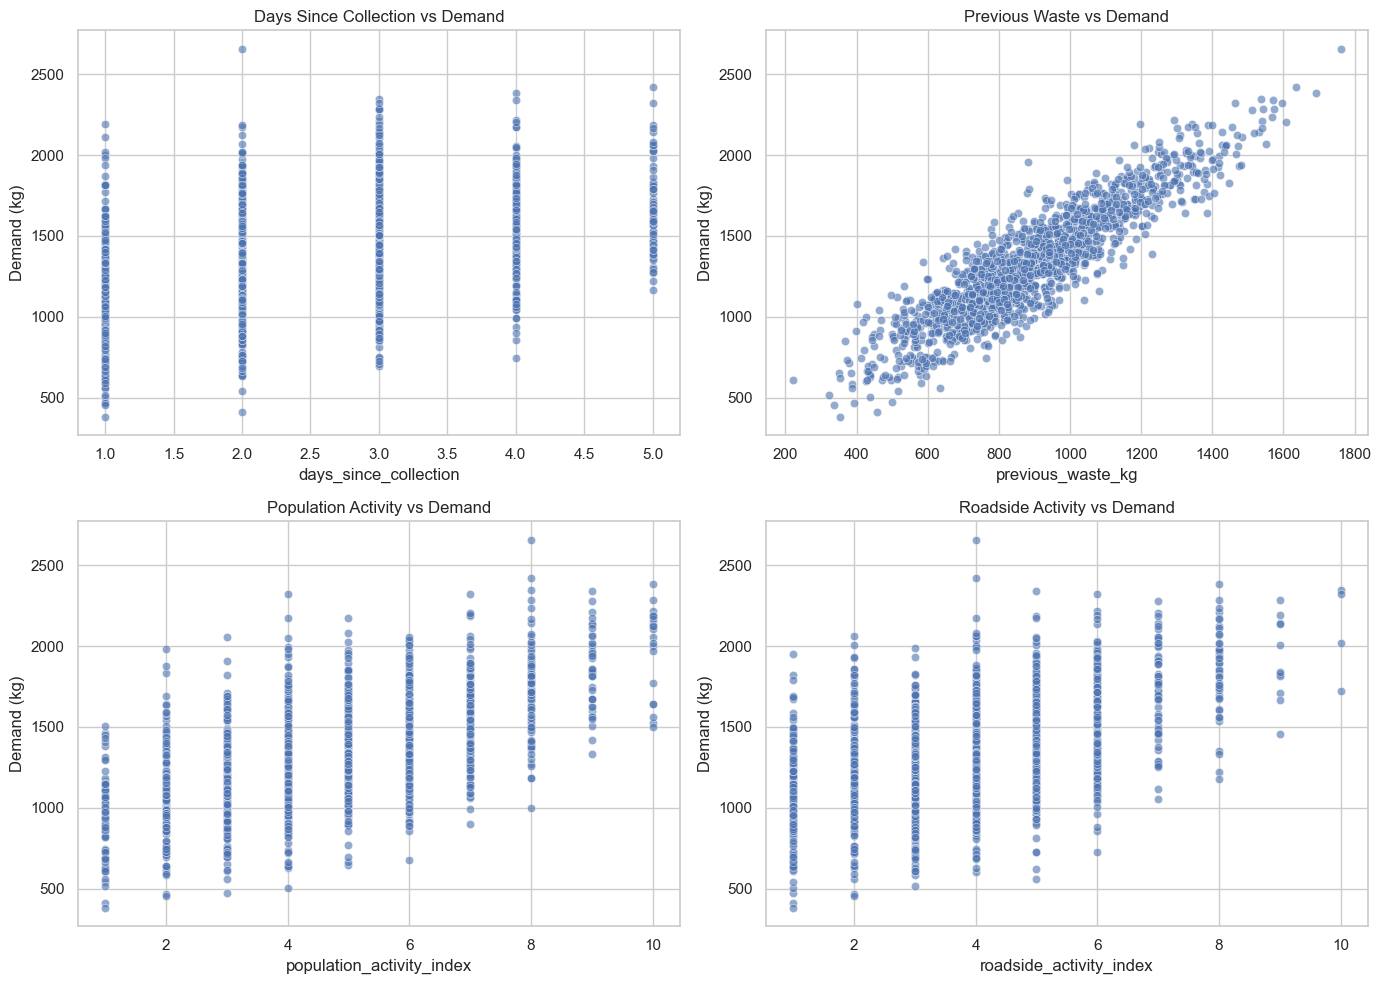

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plots = [
    ("days_since_collection", "Days Since Collection vs Demand"),
    ("previous_waste_kg", "Previous Waste vs Demand"),
    ("population_activity_index", "Population Activity vs Demand"),
    ("roadside_activity_index", "Roadside Activity vs Demand")
]

for ax, (feature, title) in zip(axes.ravel(), plots):
    sns.scatterplot(data=df, x=feature, y=TARGET, alpha=0.6, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Demand (kg)")

plt.tight_layout()
plt.show()

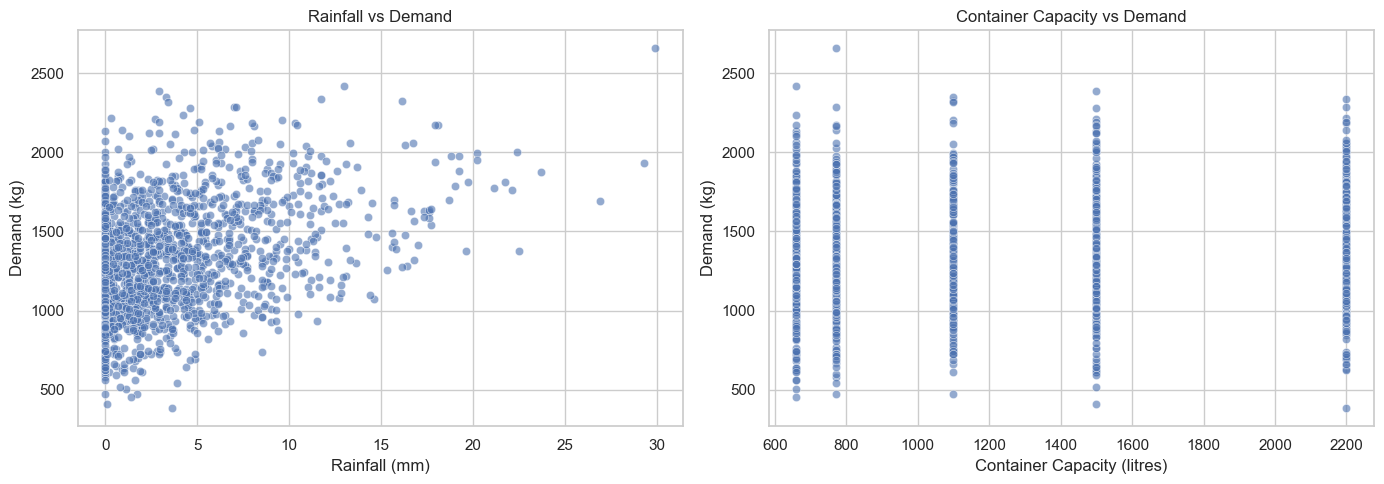

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="rainfall_mm", y=TARGET, alpha=0.6, ax=axes[0])
axes[0].set_title("Rainfall vs Demand")
axes[0].set_xlabel("Rainfall (mm)")
axes[0].set_ylabel("Demand (kg)")

sns.scatterplot(data=df, x="container_capacity_litres", y=TARGET, alpha=0.6, ax=axes[1])
axes[1].set_title("Container Capacity vs Demand")
axes[1].set_xlabel("Container Capacity (litres)")
axes[1].set_ylabel("Demand (kg)")

plt.tight_layout()
plt.show()

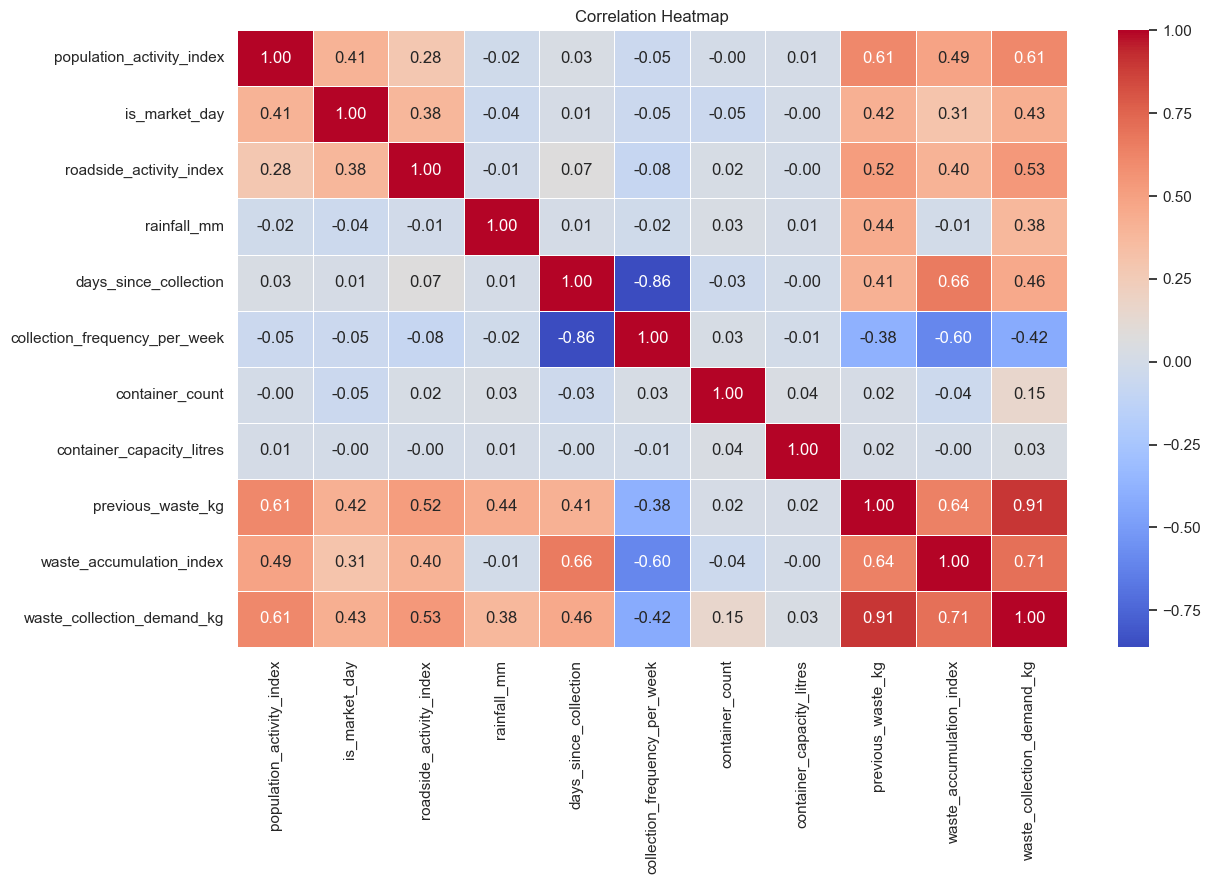

In [23]:
corr_cols = [
    "population_activity_index", "is_market_day",
    "roadside_activity_index", "rainfall_mm",
    "days_since_collection", "collection_frequency_per_week",
    "container_count", "container_capacity_litres",
    "previous_waste_kg", "waste_accumulation_index",
    TARGET
]

plt.figure(figsize=(13, 9))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4. Prepare the Data for Machine Learning

In [24]:
# Create calendar features from the date.
df["year"] = df["date"].dt.year
df["day_of_month"] = df["date"].dt.day

# Remove identifier, raw date, and target-leakage feature.
# container_utilization_ratio was calculated using the current target
# in the synthetic dataset, so retaining it would leak the answer.
model_df = df.drop(
    columns=["date", "record_id", "container_utilization_ratio"]
).copy()

X = model_df.drop(columns=[TARGET])
y = model_df[TARGET]

print("Predictor columns:", X.shape[1])
print("Target records:", len(y))

Predictor columns: 17
Target records: 1500


In [19]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

Categorical features: ['month', 'day_of_week', 'location', 'area_type']

Numerical features: ['is_weekend', 'population_activity_index', 'is_market_day', 'roadside_activity_index', 'rainfall_mm', 'days_since_collection', 'collection_frequency_per_week', 'container_count', 'container_capacity_litres', 'previous_waste_kg', 'waste_accumulation_index', 'year', 'day_of_month']


## 5. Train-Test Split and Preprocessing

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1200
Testing records: 300


In [30]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 6. Model 1 — Linear Regression

In [31]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("===== LINEAR REGRESSION =====")
print(f"MAE  : {linear_mae:,.2f} kg")
print(f"RMSE : {linear_rmse:,.2f} kg")
print(f"R²   : {linear_r2:.4f}")

===== LINEAR REGRESSION =====
MAE  : 91.47 kg
RMSE : 115.63 kg
R²   : 0.8910


## 7. Model 2 — Decision Tree Regressor

In [32]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

print("===== DECISION TREE REGRESSOR =====")
print(f"MAE  : {tree_mae:,.2f} kg")
print(f"RMSE : {tree_rmse:,.2f} kg")
print(f"R²   : {tree_r2:.4f}")

===== DECISION TREE REGRESSOR =====
MAE  : 130.90 kg
RMSE : 168.81 kg
R²   : 0.7678


## 8. Model 3 — Random Forest Regressor

In [33]:
forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))
forest_r2 = r2_score(y_test, forest_pred)

print("===== RANDOM FOREST REGRESSOR =====")
print(f"MAE  : {forest_mae:,.2f} kg")
print(f"RMSE : {forest_rmse:,.2f} kg")
print(f"R²   : {forest_r2:.4f}")

===== RANDOM FOREST REGRESSOR =====
MAE  : 107.51 kg
RMSE : 138.27 kg
R²   : 0.8442


## 9. Compare Model Performance

In [34]:
%pip install jinja2

results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [linear_mae, tree_mae, forest_mae],
    "RMSE": [linear_rmse, tree_rmse, forest_rmse],
    "R²": [linear_r2, tree_r2, forest_r2]
}).sort_values("R²", ascending=False).reset_index(drop=True)

display(results.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R²": "{:.4f}"
}))


[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


,Model,MAE,RMSE,R²
0,Linear Regression,91.47,115.63,0.8910
1,Random Forest,107.51,138.27,0.8442
2,Decision Tree,130.90,168.81,0.7678


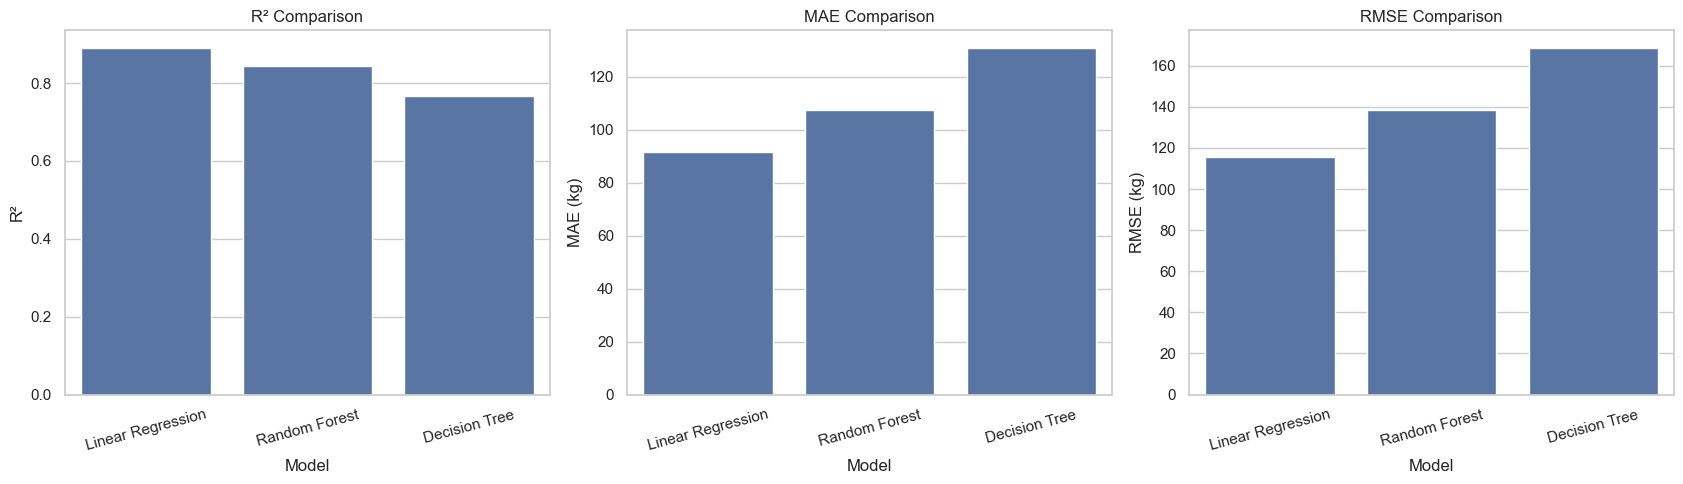

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=results, x="Model", y="R²", errorbar=None, ax=axes[0])
axes[0].set_title("R² Comparison")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(data=results, x="Model", y="MAE", errorbar=None, ax=axes[1])
axes[1].set_title("MAE Comparison")
axes[1].set_ylabel("MAE (kg)")
axes[1].tick_params(axis="x", rotation=15)

sns.barplot(data=results, x="Model", y="RMSE", errorbar=None, ax=axes[2])
axes[2].set_title("RMSE Comparison")
axes[2].set_ylabel("RMSE (kg)")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

For regression, MAE and RMSE are expressed in the same unit as the target, kilograms in this project. R² measures the proportion of target variance explained by the model. citeturn0search0turn0search4

## 10. Actual vs Predicted Demand

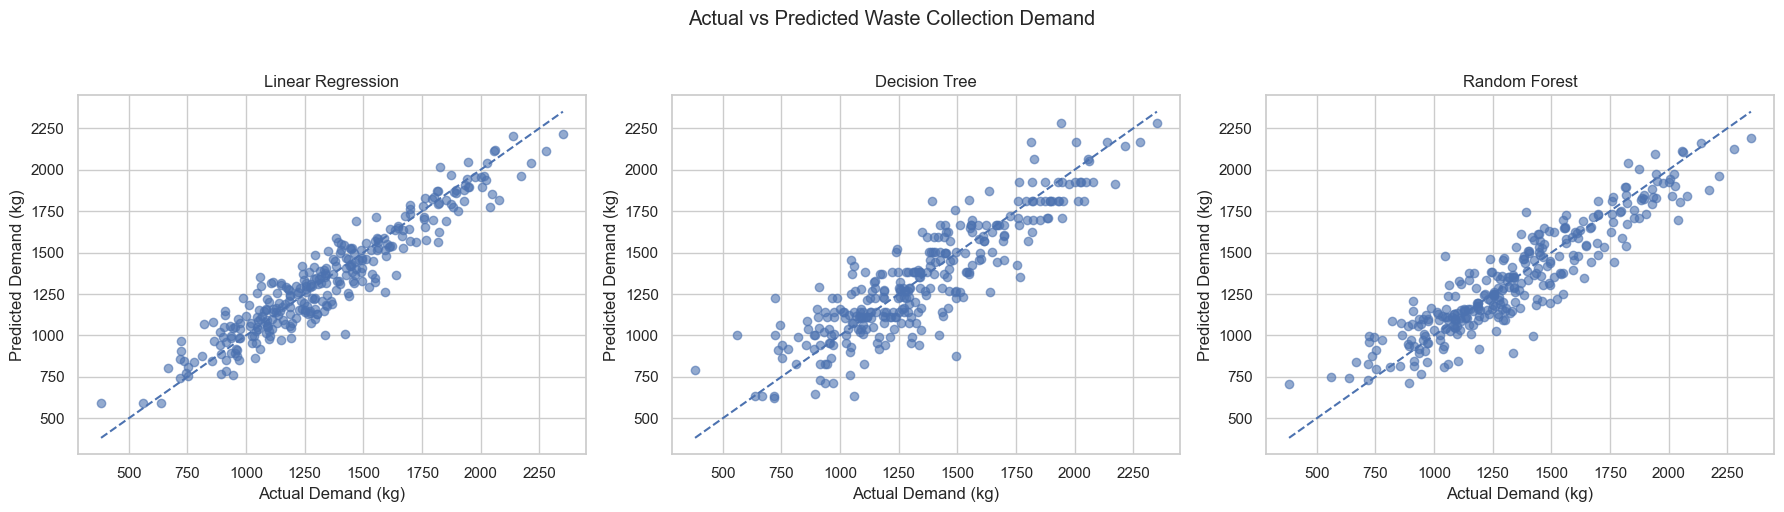

In [36]:
predictions = {
    "Linear Regression": linear_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.6)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    ax.plot([low, high], [low, high], linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual Demand (kg)")
    ax.set_ylabel("Predicted Demand (kg)")

plt.suptitle("Actual vs Predicted Waste Collection Demand", y=1.02)
plt.tight_layout()
plt.show()

## 11. Residual and Error Analysis

In [37]:
best_model_name = results.iloc[0]["Model"]
best_pred = predictions[best_model_name]
residuals = y_test.to_numpy() - best_pred

print("Model selected for diagnostics:", best_model_name)
print(f"Mean residual: {residuals.mean():,.2f} kg")
print(f"Mean absolute residual: {np.abs(residuals).mean():,.2f} kg")

Model selected for diagnostics: Linear Regression
Mean residual: 10.59 kg
Mean absolute residual: 91.47 kg


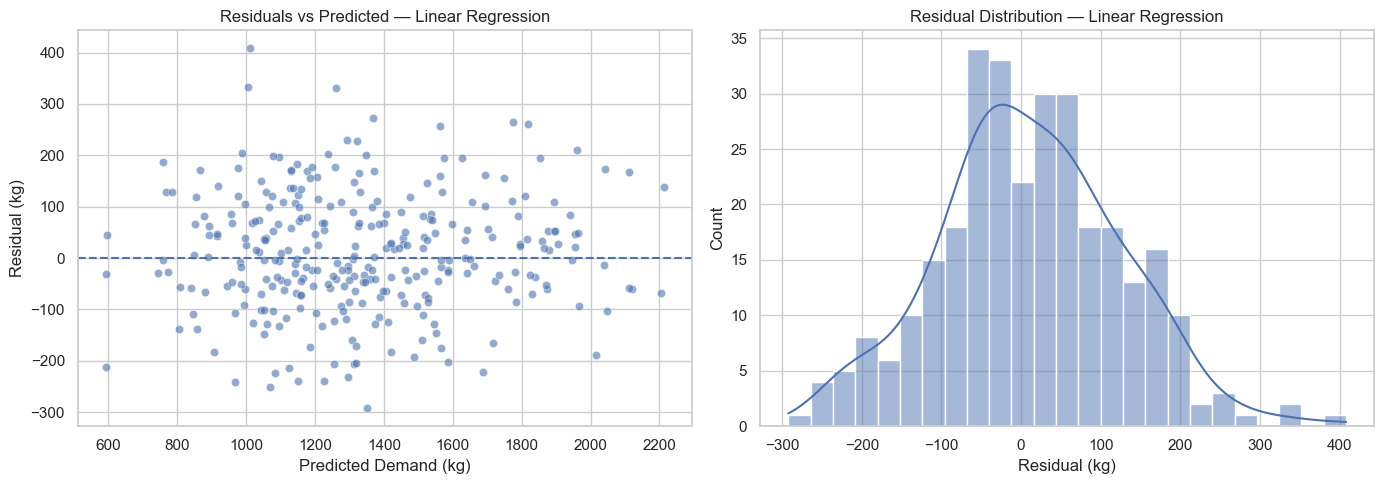

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=best_pred, y=residuals, alpha=0.6, ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_title(f"Residuals vs Predicted — {best_model_name}")
axes[0].set_xlabel("Predicted Demand (kg)")
axes[0].set_ylabel("Residual (kg)")

sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
axes[1].set_title(f"Residual Distribution — {best_model_name}")
axes[1].set_xlabel("Residual (kg)")

plt.tight_layout()
plt.show()

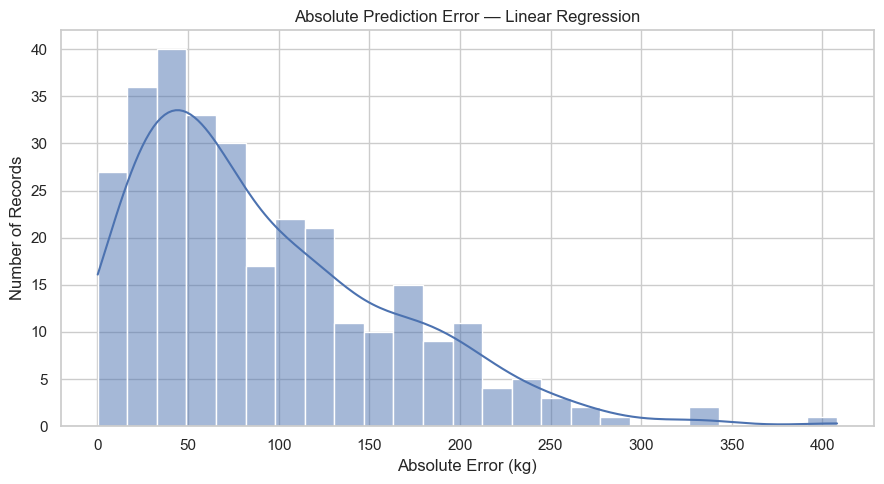

In [39]:
absolute_errors = np.abs(y_test.to_numpy() - best_pred)

plt.figure(figsize=(9, 5))
sns.histplot(absolute_errors, bins=25, kde=True)
plt.title(f"Absolute Prediction Error — {best_model_name}")
plt.xlabel("Absolute Error (kg)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 12. Feature Importance

In [40]:
rf_preprocessor = forest_model.named_steps["preprocessor"]
rf_estimator = forest_model.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(20).round(4))

,Feature,Importance
9,num__previous_waste_kg,0.8389
10,num__waste_accumulation_index,0.0388
7,num__container_count,0.0224
4,num__rainfall_mm,0.0138
12,num__day_of_month,0.0112
1,num__population_activity_index,0.0108
3,num__roadside_activity_index,0.0086
6,num__collection_frequency_per_week,0.0063
8,num__container_capacity_litres,0.0063
5,num__days_since_collection,0.0034


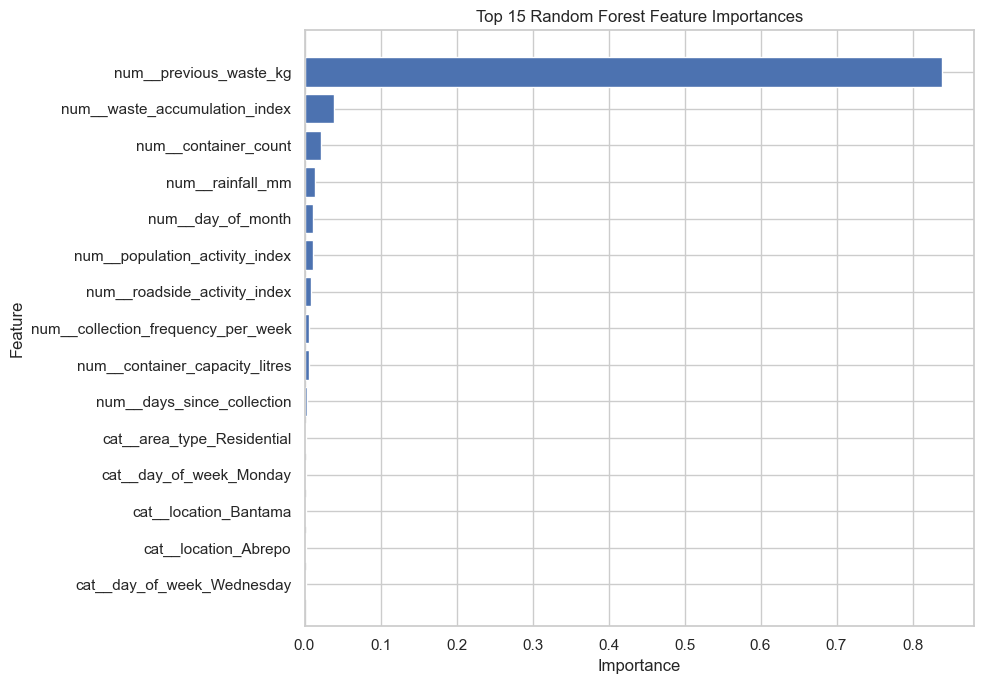

In [41]:
top = importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top["Feature"], top["Importance"])
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 13. Actual vs Predicted Demand by Location

In [35]:
location_results = X_test[["location"]].copy()
location_results["Actual"] = y_test.values
location_results["Predicted"] = best_pred

location_summary = (
    location_results
    .groupby("location")[["Actual", "Predicted"]]
    .mean()
    .sort_values("Actual", ascending=False)
)

display(location_summary.round(2))

,Actual,Predicted
location,,
Kumasi Central Market,1895.76,1872.79
Tafo,1591.18,1573.00
Suame,1441.40,1445.79
Manhyia,1377.15,1342.49
Sofoline,1363.76,1368.49
Ayigya,1361.99,1318.95
Asokwa,1315.65,1326.08
Bantama,1261.41,1280.83
Oforikrom,1231.86,1179.30


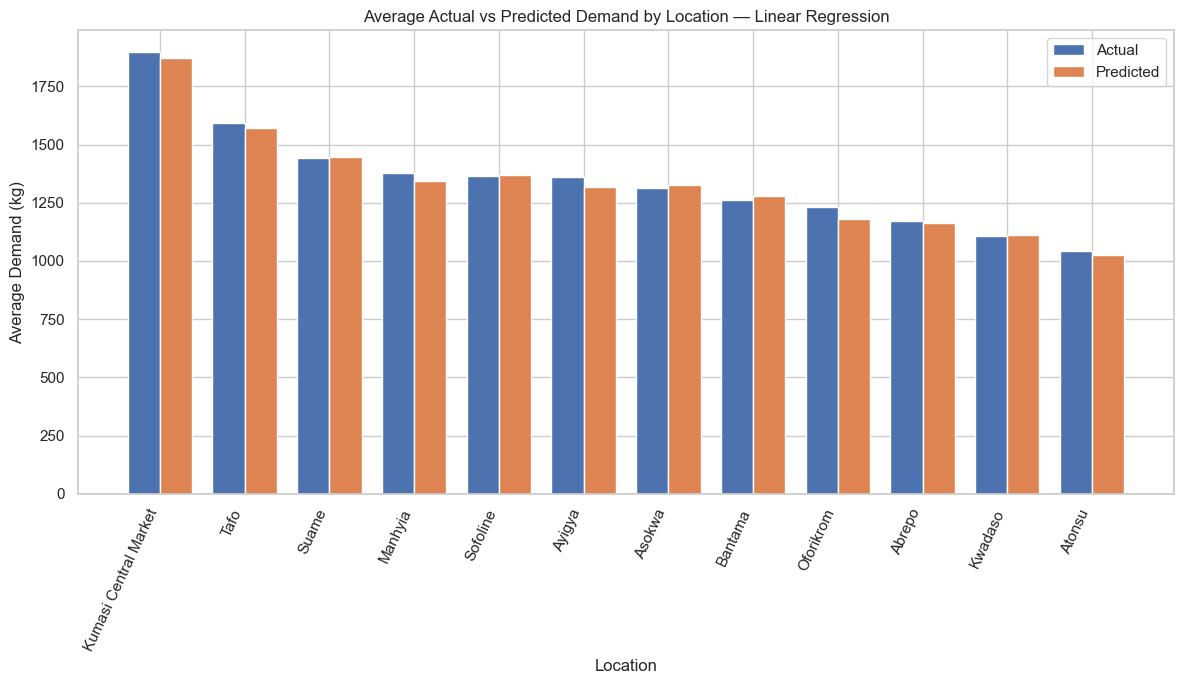

In [36]:
plot_data = location_summary.reset_index()
x = np.arange(len(plot_data))
width = 0.38

plt.figure(figsize=(12, 7))
plt.bar(x - width/2, plot_data["Actual"], width, label="Actual")
plt.bar(x + width/2, plot_data["Predicted"], width, label="Predicted")

plt.xticks(x, plot_data["location"], rotation=65, ha="right")
plt.title(f"Average Actual vs Predicted Demand by Location — {best_model_name}")
plt.xlabel("Location")
plt.ylabel("Average Demand (kg)")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Example Operational Prediction

In [42]:
example_record = pd.DataFrame([{
    "month": "September",
    "day_of_week": "Tuesday",
    "is_weekend": 0,
    "location": "Bantama",
    "area_type": "Mixed",
    "population_activity_index": 72,
    "is_market_day": 1,
    "roadside_activity_index": 65,
    "rainfall_mm": 8.5,
    "days_since_collection": 3,
    "collection_frequency_per_week": 3,
    "container_count": 8,
    "container_capacity_litres": 660,
    "previous_waste_kg": 1350,
    "waste_accumulation_index": 68,
    "year": 2026,
    "day_of_month": 23
}])

example_prediction = forest_model.predict(example_record)[0]

print(f"Example predicted waste collection demand: {example_prediction:,.2f} kg")
display(example_record)

Example predicted waste collection demand: 2,025.91 kg


,month,day_of_week,is_weekend,location,area_type,population_activity_index,is_market_day,roadside_activity_index,rainfall_mm,days_since_collection,collection_frequency_per_week,container_count,container_capacity_litres,previous_waste_kg,waste_accumulation_index,year,day_of_month
0,September,Tuesday,0,Bantama,Mixed,72,1,65,8.5,3,3,8,660,1350,68,2026,23


## 15. Final Model Summary

In [44]:
final = results.iloc[0]

print("=" * 45)
print("FINAL MODEL SUMMARY")
print("=" * 45)
print(f"Selected model : {final['Model']}")
print(f"MAE            : {final['MAE']:,.2f} kg")
print(f"RMSE           : {final['RMSE']:,.2f} kg")
print(f"R²             : {final['R²']:.4f}")
print()


FINAL MODEL SUMMARY
Selected model : Linear Regression
MAE            : 91.47 kg
RMSE           : 115.63 kg
R²             : 0.8910



## 16. Conclusion

The final workflow is designed specifically for waste collection demand 

It combines:
- operationally meaningful EDA,
- leakage control,
- categorical and numerical preprocessing,
- multiple regression algorithms,
- test-set evaluation,
- prediction-error diagnostics,
- feature importance,
- and location-level prediction analysis.

The model comparison provides a data-driven basis for selecting the model used for the final prediction demonstration.

